<a href="https://colab.research.google.com/github/danishsuryarirta-create/Tugas_Akhir/blob/main/Osteoporosis_TA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Klasifikasi Osteoporosis: Baseline vs Hyperparameter Tuning (Optuna)

**Alur penelitian:** Dataset → Data Understanding → Split (80/20) → Preprocessing → Model (RF, XGBoost, LightGBM; baseline dan tuned) → Tuning Optuna (5-fold CV di data train) → Evaluasi → Model Terbaik

| Tahap | Isi |
|---|---|
| 1 | Setup dan konfigurasi |
| 2 | Input dataset |
| 3 | Data understanding |
| 4 | Split data |
| 5 | Preprocessing |
| 6 | Helper evaluasi model |
| 7 | Model baseline |
| 8 | Hyperparameter tuning (Optuna) |
| 9 | Evaluasi: baseline vs tuned |
| 10 | Analisis proses Optuna |
| 11 | Model terbaik & penyimpanan hasil |

## 1. Setup

In [1]:
!pip install -q optuna xgboost lightgbm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 8.9 MB/s eta 0:00:00


In [2]:
import json
import time
import warnings
warnings.filterwarnings("ignore")

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import optuna
from optuna.samplers import TPESampler
from scipy import stats

from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix,
                             classification_report)
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     RepeatedStratifiedKFold, cross_val_score)
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)
optuna.logging.set_verbosity(optuna.logging.WARNING)

# ---------- Konfigurasi ----------
RANDOM_STATE = 42
TARGET       = "Osteoporosis"
target       = TARGET
N_TRIALS     = 100        # jumlah trial Optuna per model (coba 20-30 dulu untuk uji kode)
N_FOLDS      = 5          # jumlah fold cross-validation di data train
SCORING      = "f1"       # metrik yang dioptimalkan Optuna: "f1" atau "roc_auc"

## 2. Input Dataset

In [14]:
df = pd.read_csv('osteoporosis.csv', keep_default_na=False)
print(f'Shape dataset : {df.shape}')
print(f'Jumlah baris  : {df.shape[0]:,}')
print(f'Jumlah kolom  : {df.shape[1]}')

Shape dataset : (1958, 16)
Jumlah baris  : 1,958
Jumlah kolom  : 16


## 3. Data Understanding

### 3.1 Cek Struktur Data

In [15]:
df.head()

,Id,Age,Gender,Hormonal Changes,Family History,Race/Ethnicity,Body Weight,Calcium Intake,Vitamin D Intake,Physical Activity,Smoking,Alcohol Consumption,Medical Conditions,Medications,Prior Fractures,Osteoporosis
0,1734616,69,Female,Normal,Yes,Asian,Underweight,Low,Sufficient,Sedentary,Yes,Moderate,Rheumatoid Arthritis,Corticosteroids,Yes,1
1,1419098,32,Female,Normal,Yes,Asian,Underweight,Low,Sufficient,Sedentary,No,None,None,None,Yes,1
2,1797916,89,Female,Postmenopausal,No,Caucasian,Normal,Adequate,Sufficient,Active,No,Moderate,Hyperthyroidism,Corticosteroids,No,1
3,1805337,78,Female,Normal,No,Caucasian,Underweight,Adequate,Insufficient,Sedentary,Yes,None,Rheumatoid Arthritis,Corticosteroids,No,1
4,1351334,38,Male,Postmenopausal,Yes,African American,Normal,Low,Sufficient,Active,Yes,None,Rheumatoid Arthritis,None,Yes,1


In [16]:
print("Jumlah baris & kolom :", df.shape)
print("\n=== Info Dataset ===")
df.info()

Jumlah baris & kolom : (1958, 16)

=== Info Dataset ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1958 entries, 0 to 1957
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   Id                   1958 non-null   int64 
 1   Age                  1958 non-null   int64 
 2   Gender               1958 non-null   object
 3   Hormonal Changes     1958 non-null   object
 4   Family History       1958 non-null   object
 5   Race/Ethnicity       1958 non-null   object
 6   Body Weight          1958 non-null   object
 7   Calcium Intake       1958 non-null   object
 8   Vitamin D Intake     1958 non-null   object
 9   Physical Activity    1958 non-null   object
 10  Smoking              1958 non-null   object
 11  Alcohol Consumption  1958 non-null   object
 12  Medical Conditions   1958 non-null   object
 13  Medications          1958 non-null   object
 14  Prior Fractures      1958 non-null   object
 15 

In [17]:
print("\n=== Tipe Data per Kolom ===")
print(df.dtypes)


=== Tipe Data per Kolom ===
Id                      int64
Age                     int64
Gender                 object
Hormonal Changes       object
Family History         object
Race/Ethnicity         object
Body Weight            object
Calcium Intake         object
Vitamin D Intake       object
Physical Activity      object
Smoking                object
Alcohol Consumption    object
Medical Conditions     object
Medications            object
Prior Fractures        object
Osteoporosis            int64
dtype: object


In [18]:
print("Deskripsi Dataset")
display(df.describe(include="all").T)

Deskripsi Dataset


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Id,1958.0,NaN,NaN,NaN,1549928.629724,261424.953731,1100064.0,1319163.0,1546027.5,1775870.5,1999676.0
Age,1958.0,NaN,NaN,NaN,39.101124,21.355424,18.0,21.0,32.0,53.0,90.0
Gender,1958,2,Male,992,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Hormonal Changes,1958,2,Normal,981,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Family History,1958,2,No,998,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Race/Ethnicity,1958,3,African American,681,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Body Weight,1958,2,Normal,1027,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Calcium Intake,1958,2,Low,1004,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Vitamin D Intake,1958,2,Sufficient,1011,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Physical Activity,1958,2,Active,1021,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 3.2 Cek Duplikasi

In [19]:
# Duplikat berdasarkan seluruh kolom
dup_all = df.duplicated().sum()
print("Duplikat (semua kolom)       :", dup_all)

Duplikat (semua kolom)       : 0


### 3.3 Cek Nilai Unik & Pembersihan Kolom

In [20]:
print("\n=== Jumlah Nilai Unik per Kolom ===")
print(df.nunique())


=== Jumlah Nilai Unik per Kolom ===
Id                     1958
Age                      73
Gender                    2
Hormonal Changes          2
Family History            2
Race/Ethnicity            3
Body Weight               2
Calcium Intake            2
Vitamin D Intake          2
Physical Activity         2
Smoking                   2
Alcohol Consumption       2
Medical Conditions        3
Medications               2
Prior Fractures           2
Osteoporosis              2
dtype: int64


In [21]:
# Menghapus kolom Id jika masih ada
df = df.drop(columns=['Id'], errors='ignore')

# Mencari dan menghapus kolom yang hanya punya 1 nilai unik
kolom_konstan = [col for col in df.columns if df[col].nunique() == 1]
df = df.drop(columns=kolom_konstan, errors='ignore')

print("\nKolom yang dibuang:", ['Id'] + kolom_konstan)
print("Shape setelah pembersihan:", df.shape)


Kolom yang dibuang: ['Id']
Shape setelah pembersihan: (1958, 15)


In [22]:
print("\n=== Daftar Kolom ===")
print(df.columns.tolist())


=== Daftar Kolom ===
['Age', 'Gender', 'Hormonal Changes', 'Family History', 'Race/Ethnicity', 'Body Weight', 'Calcium Intake', 'Vitamin D Intake', 'Physical Activity', 'Smoking', 'Alcohol Consumption', 'Medical Conditions', 'Medications', 'Prior Fractures', 'Osteoporosis']


### 3.4 Cek Missing Value

In [23]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)

missing_df = pd.DataFrame({
    "Jumlah Missing": missing,
    "Persentase (%)": missing_pct
})
missing_df = missing_df[missing_df["Jumlah Missing"] > 0]

if missing_df.empty:
    print("Tidak ada missing value")
else:
    print("Kolom dengan missing value:")
    display(missing_df)

    # Visualisasi
    plt.figure(figsize=(7, 3))
    sns.barplot(x=missing_df.index, y=missing_df["Persentase (%)"], color="steelblue")
    plt.title("Persentase Missing Value per Kolom")
    plt.ylabel("%")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

Tidak ada missing value


### 3.5 Analisis Deskriptif
#### 3.5.1 Distribusi Target

Osteoporosis
0    979
1    979
Name: count, dtype: int64
Osteoporosis
0    50.0 %
1    50.0 %
Name: count, dtype: object


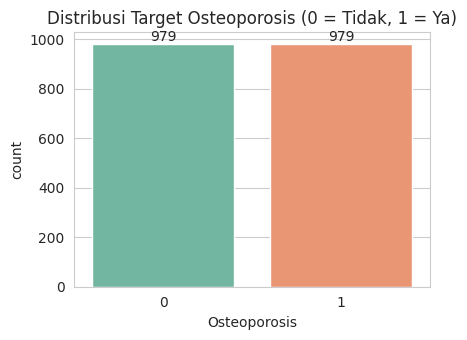

In [25]:
dist = df[target].value_counts().sort_index()
print(dist)
print((dist / len(df) * 100).round(2).astype(str) + " %")

plt.figure(figsize=(4.5, 3.5))
ax = sns.countplot(x=target, data=df, hue=target, palette="Set2", legend=False)
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.title("Distribusi Target Osteoporosis (0 = Tidak, 1 = Ya)")
plt.tight_layout()
plt.show()

#### 3.5.2 Distribusi Fitur Numerik terhadap Target

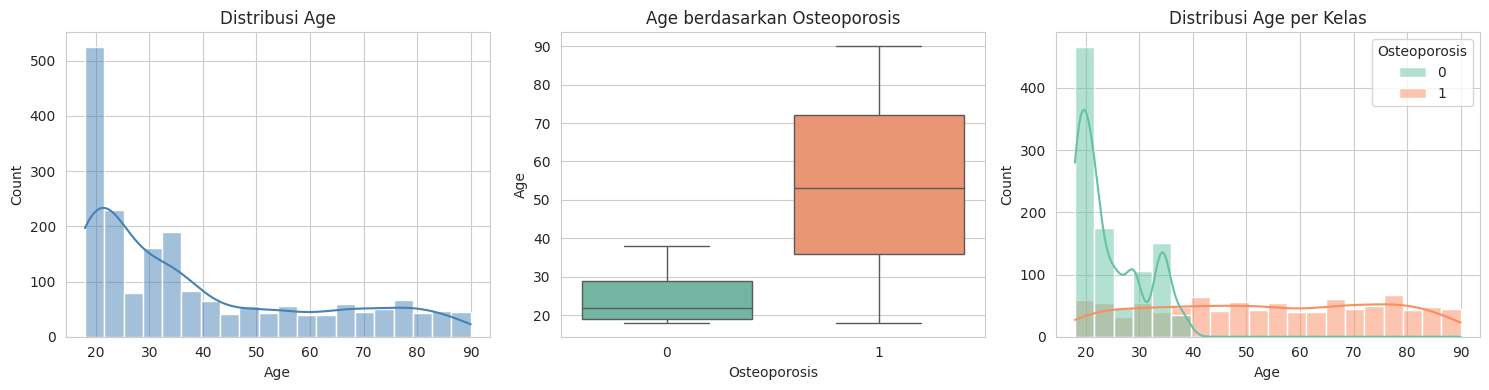

              count   mean    std   min   25%   50%   75%   max
Osteoporosis                                                   
0             979.0  24.34   6.11  18.0  19.0  22.0  29.0  38.0
1             979.0  53.86  20.96  18.0  36.0  53.0  72.0  90.0


In [26]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(df["Age"], bins=20, kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Distribusi Age")

sns.boxplot(x=target, y="Age", data=df, hue=target, palette="Set2",
            legend=False, ax=axes[1])
axes[1].set_title("Age berdasarkan Osteoporosis")

sns.histplot(data=df, x="Age", hue=target, bins=20, kde=True,
             palette="Set2", ax=axes[2])
axes[2].set_title("Distribusi Age per Kelas")

plt.tight_layout()
plt.show()

print(df.groupby(target)["Age"].describe().round(2))

#### 3.5.3 Distribusi Fitur Kategorikal terhadap Target

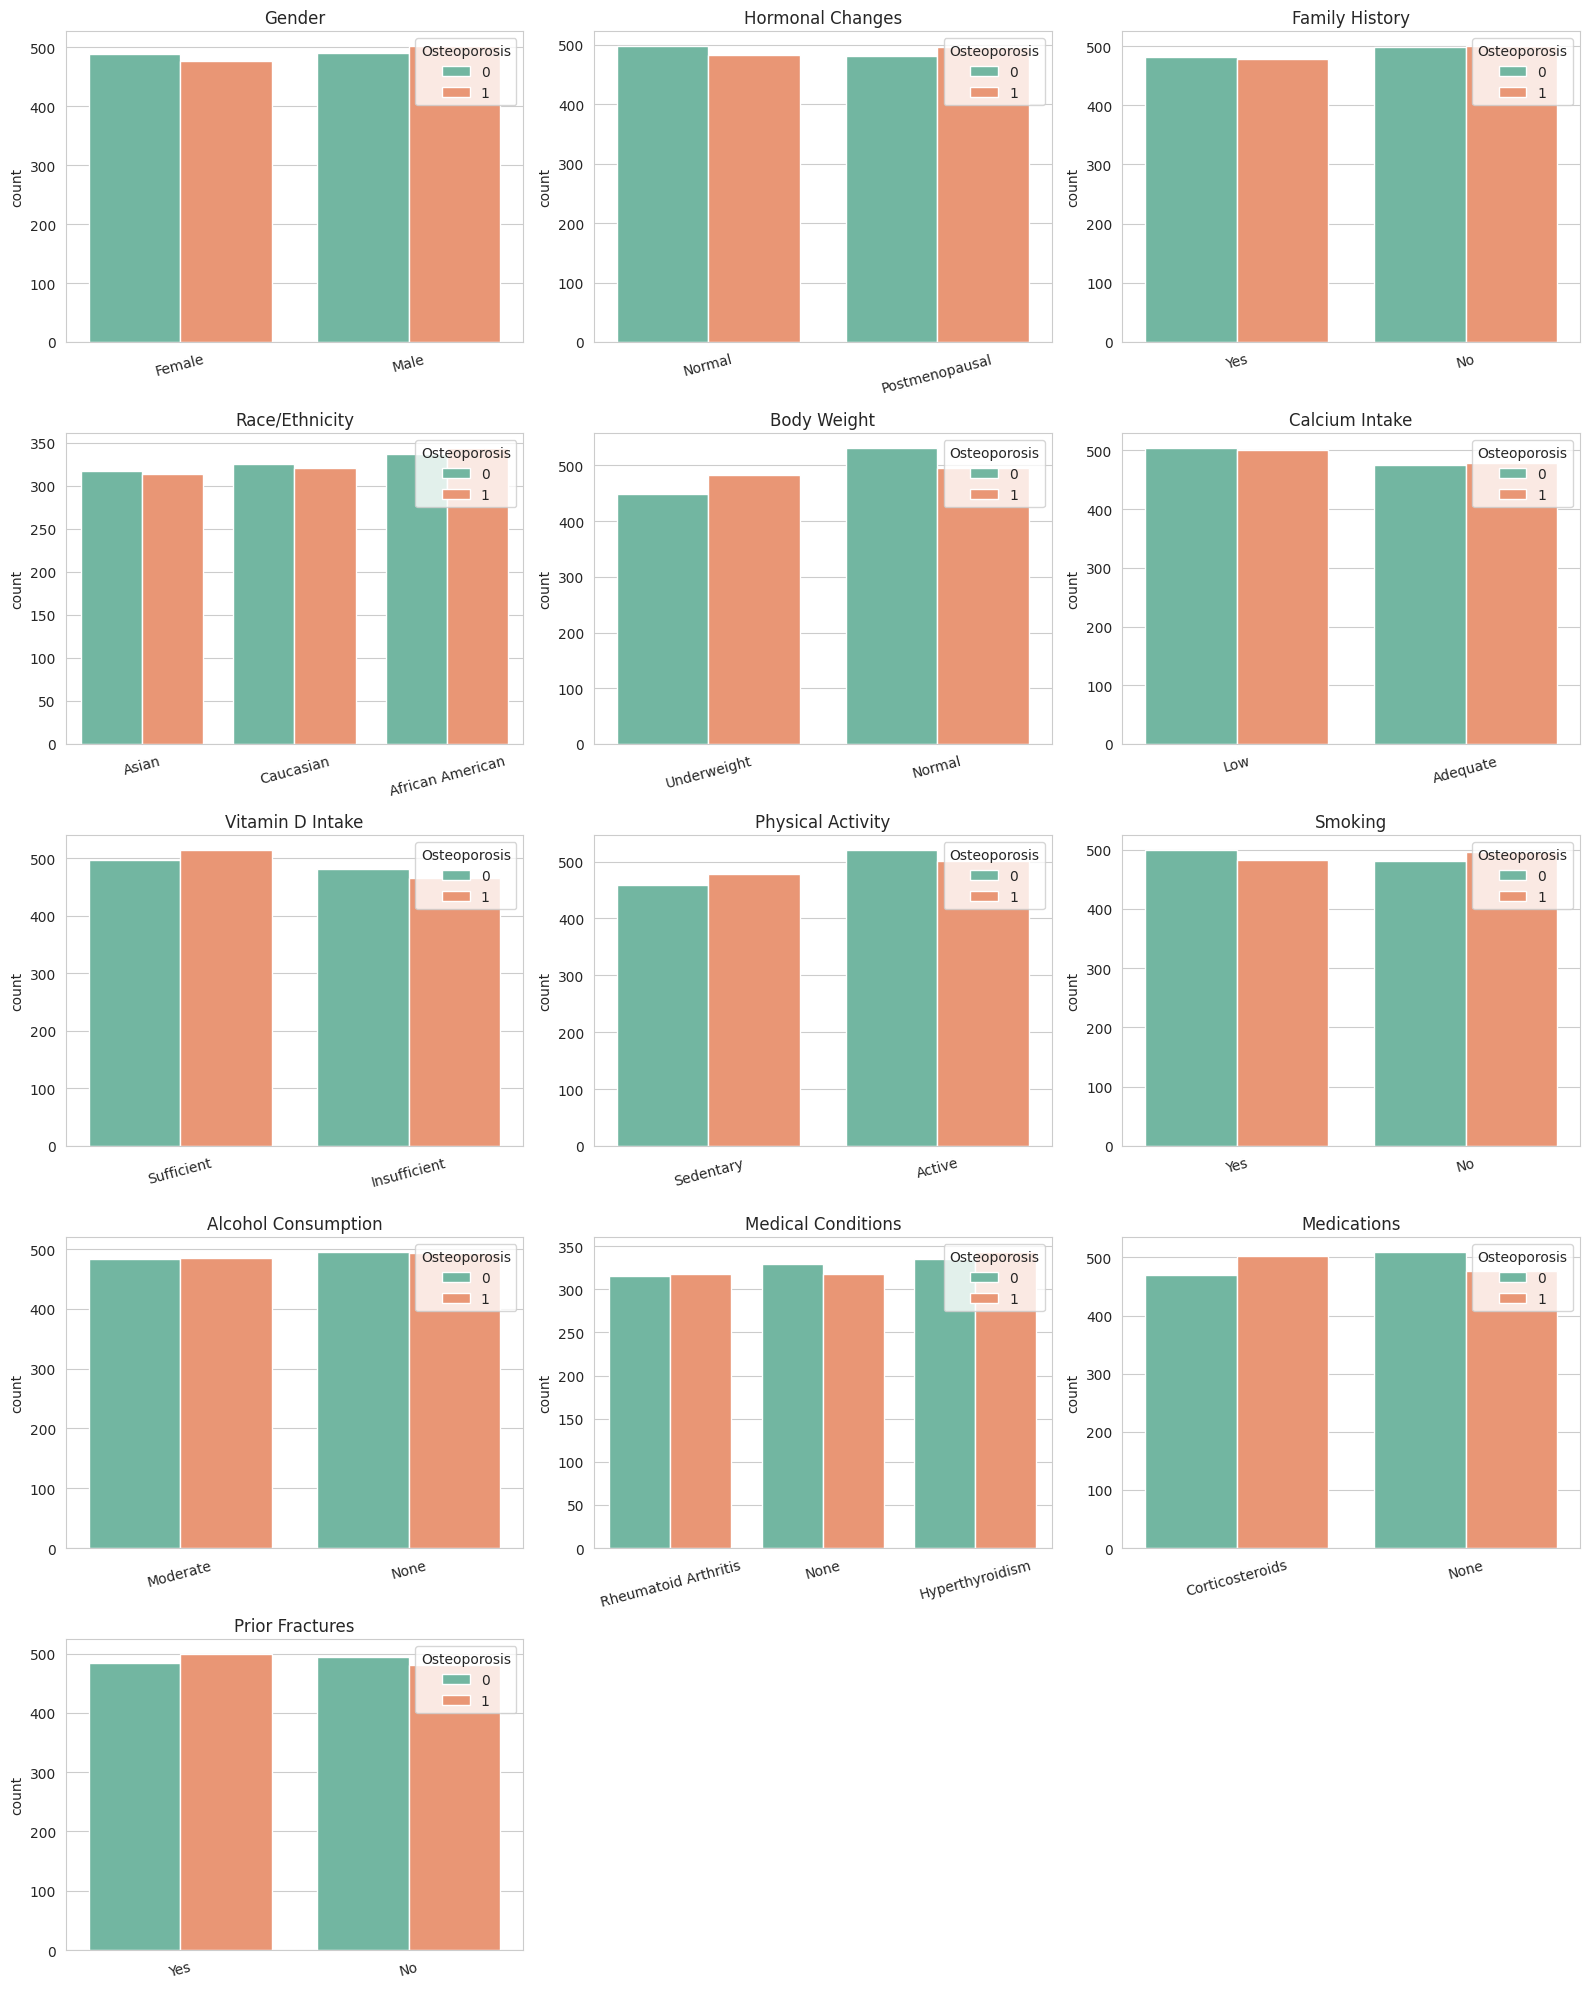

In [27]:
n = len(cat_cols)
ncols = 3
nrows = int(np.ceil(n / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4 * nrows))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    sns.countplot(x=col, hue=target, data=df, palette="Set2", ax=axes[i])
    axes[i].set_title(col)
    axes[i].set_xlabel("")
    axes[i].tick_params(axis="x", rotation=15)

for j in range(i + 1, len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

#### 3.5.5 Heatmap Korelasi

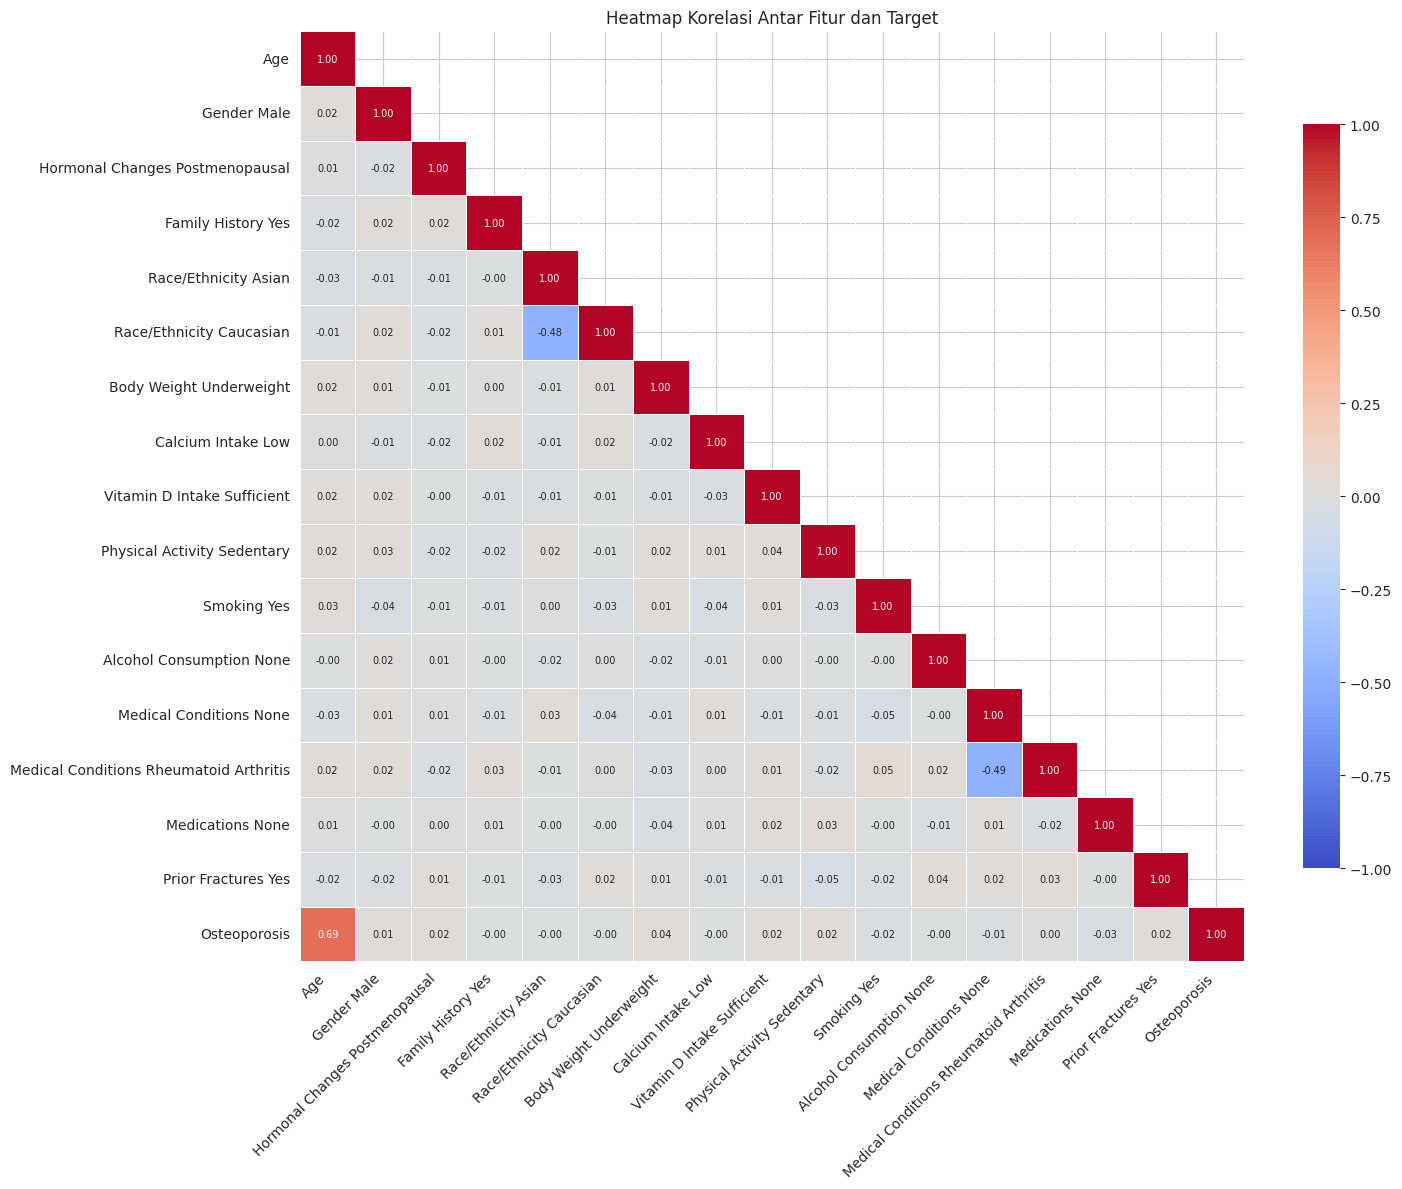

Korelasi terhadap Osteoporosis (diurutkan dari yang terkuat):
Age                                        0.691
Body Weight Underweight                    0.036
Medications None                          -0.034
Physical Activity Sedentary                0.019
Vitamin D Intake Sufficient                0.017
Smoking Yes                               -0.016
Prior Fractures Yes                        0.015
Hormonal Changes Postmenopausal            0.015
Gender Male                                0.012
Medical Conditions None                   -0.012
Race/Ethnicity Caucasian                  -0.004
Calcium Intake Low                        -0.004
Race/Ethnicity Asian                      -0.003
Medical Conditions Rheumatoid Arthritis    0.003
Family History Yes                        -0.002
Alcohol Consumption None                  -0.002
Name: Osteoporosis, dtype: float64


In [28]:
df_corr = pd.get_dummies(df, drop_first=True, dtype=int)
df_corr.columns = df_corr.columns.str.replace("_", " ")

# Taruh target di kolom terakhir supaya mudah dibaca
kolom = [c for c in df_corr.columns if c != target] + [target]
corr = df_corr[kolom].corr()

# k=1 -> diagonal (korelasi dengan diri sendiri = 1) tetap ditampilkan
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

plt.figure(figsize=(15, 12))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, vmin=-1, vmax=1, linewidths=0.5,
            annot_kws={"size": 7}, cbar_kws={"shrink": 0.8})
plt.title("Heatmap Korelasi Antar Fitur dan Target")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

corr_target = corr[target].drop(target).sort_values(key=abs, ascending=False)
print("Korelasi terhadap Osteoporosis (diurutkan dari yang terkuat):")
print(corr_target.round(3))

#### 3.5.6 Proporsi Osteoporosis per Kategori

In [29]:
for col in cat_cols:
    r = df.groupby(col)[target].mean().round(3)
    print(f"{col:22s}", r.to_dict())

Gender                 {'Female': 0.494, 'Male': 0.506}
Hormonal Changes       {'Normal': 0.492, 'Postmenopausal': 0.508}
Family History         {'No': 0.501, 'Yes': 0.499}
Race/Ethnicity         {'African American': 0.505, 'Asian': 0.498, 'Caucasian': 0.497}
Body Weight            {'Normal': 0.483, 'Underweight': 0.519}
Calcium Intake         {'Adequate': 0.502, 'Low': 0.498}
Vitamin D Intake       {'Insufficient': 0.491, 'Sufficient': 0.508}
Physical Activity      {'Active': 0.491, 'Sedentary': 0.51}
Smoking                {'No': 0.508, 'Yes': 0.492}
Alcohol Consumption    {'Moderate': 0.501, 'None': 0.499}
Medical Conditions     {'Hyperthyroidism': 0.506, 'None': 0.491, 'Rheumatoid Arthritis': 0.502}
Medications            {'Corticosteroids': 0.517, 'None': 0.483}
Prior Fractures        {'No': 0.492, 'Yes': 0.508}


## 4. Split Data (80% Train, 20% Test)

In [30]:
df_train, df_test = train_test_split(
    df,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=df[target]
)

print(f"Data train : {df_train.shape}")
print(f"Data test  : {df_test.shape}")

# Cek proporsi kelas setelah split
cek = pd.DataFrame({
    "Seluruh data": df[target].value_counts(normalize=True).round(3),
    "Train": df_train[target].value_counts(normalize=True).round(3),
    "Test": df_test[target].value_counts(normalize=True).round(3),
})
display(cek)

print("\nJumlah per kelas:")
print("Train:", df_train[target].value_counts().to_dict())
print("Test :", df_test[target].value_counts().to_dict())

Data train : (1566, 15)
Data test  : (392, 15)


,Seluruh data,Train,Test
Osteoporosis,,,
0,0.5,0.5,0.5
1,0.5,0.5,0.5



Jumlah per kelas:
Train: {0: 783, 1: 783}
Test : {1: 196, 0: 196}


## 5. Preprocessing

In [31]:
# 1. Pisahkan fitur (X) dan target (y)
X_train = df_train.drop(columns=[target])
y_train = df_train[target]
X_test  = df_test.drop(columns=[target])
y_test  = df_test[target]

# 2. Tentukan kolom untuk tiap jenis encoding
ohe_cols = ["Race/Ethnicity", "Medical Conditions"]                  # kategori > 2
le_cols  = [c for c in X_train.select_dtypes(exclude="number").columns
            if c not in ohe_cols]                                    # kategori biner

# 3. Label Encoding (fit hanya di data train)
X_train_enc = X_train.copy()
X_test_enc  = X_test.copy()
label_encoders = {}

for col in le_cols:
    le = LabelEncoder()
    X_train_enc[col] = le.fit_transform(X_train[col])
    X_test_enc[col]  = le.transform(X_test[col])
    label_encoders[col] = le

# 4. One-Hot Encoding (fit hanya di data train)
ohe = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
ohe.fit(X_train[ohe_cols])

def terapkan_ohe(X_enc, X_raw):
    ohe_df = pd.DataFrame(
        ohe.transform(X_raw[ohe_cols]),
        columns=ohe.get_feature_names_out(ohe_cols),
        index=X_raw.index
    )
    return pd.concat([X_enc.drop(columns=ohe_cols), ohe_df], axis=1)

X_train_enc = terapkan_ohe(X_train_enc, X_train)
X_test_enc  = terapkan_ohe(X_test_enc, X_test)

# 5. Rapikan nama kolom (hindari spasi/simbol agar aman untuk XGBoost & LightGBM)
for d in (X_train_enc, X_test_enc):
    d.columns = d.columns.str.replace(r"[^0-9a-zA-Z_]", "_", regex=True)

print("X_train :", X_train_enc.shape)
print("X_test  :", X_test_enc.shape)
print("Kolom sama antara train & test:", list(X_train_enc.columns) == list(X_test_enc.columns))

print("\nMapping Label Encoding:")
for col, le in label_encoders.items():
    print(f"  {col:20s}", dict(zip(le.classes_, le.transform(le.classes_))))

X_train_enc.head()

X_train : (1566, 18)
X_test  : (392, 18)
Kolom sama antara train & test: True

Mapping Label Encoding:
  Gender               {'Female': np.int64(0), 'Male': np.int64(1)}
  Hormonal Changes     {'Normal': np.int64(0), 'Postmenopausal': np.int64(1)}
  Family History       {'No': np.int64(0), 'Yes': np.int64(1)}
  Body Weight          {'Normal': np.int64(0), 'Underweight': np.int64(1)}
  Calcium Intake       {'Adequate': np.int64(0), 'Low': np.int64(1)}
  Vitamin D Intake     {'Insufficient': np.int64(0), 'Sufficient': np.int64(1)}
  Physical Activity    {'Active': np.int64(0), 'Sedentary': np.int64(1)}
  Smoking              {'No': np.int64(0), 'Yes': np.int64(1)}
  Alcohol Consumption  {'Moderate': np.int64(0), 'None': np.int64(1)}
  Medications          {'Corticosteroids': np.int64(0), 'None': np.int64(1)}
  Prior Fractures      {'No': np.int64(0), 'Yes': np.int64(1)}


,Age,Gender,Hormonal_Changes,Family_History,Body_Weight,Calcium_Intake,Vitamin_D_Intake,Physical_Activity,Smoking,Alcohol_Consumption,Medications,Prior_Fractures,Race_Ethnicity_African_American,Race_Ethnicity_Asian,Race_Ethnicity_Caucasian,Medical_Conditions_Hyperthyroidism,Medical_Conditions_None,Medical_Conditions_Rheumatoid_Arthritis
1473,25,0,1,0,0,1,0,1,0,0,0,0,0.0,0.0,1.0,1.0,0.0,0.0
1394,34,1,1,1,0,1,0,0,0,0,1,0,0.0,1.0,0.0,0.0,0.0,1.0
718,25,0,1,0,1,1,0,0,0,0,1,0,0.0,0.0,1.0,1.0,0.0,0.0
868,64,0,1,1,1,0,0,1,1,0,0,0,1.0,0.0,0.0,0.0,1.0,0.0
256,44,1,1,1,1,0,1,0,0,0,1,1,1.0,0.0,0.0,1.0,0.0,0.0


## 6. Helper: Fungsi Evaluasi Model

In [34]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report)

def evaluate_model(name, model, X_train, X_test, y_train, y_test, fit=True):
    if fit:
        model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]   # probabilitas kelas 1, untuk ROC-AUC

    acc  = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec  = recall_score(y_test, y_pred, zero_division=0)
    f1   = f1_score(y_test, y_pred, zero_division=0)
    auc  = roc_auc_score(y_test, y_proba)
    cm   = confusion_matrix(y_test, y_pred)

    print(f'\n{"="*55}')
    print(f'  Model : {name}')
    print(f'{"="*55}')
    print(f'  Accuracy  : {acc:.4f}')
    print(f'  Precision : {prec:.4f}')
    print(f'  Recall    : {rec:.4f}')
    print(f'  F1-Score  : {f1:.4f}')
    print(f'  ROC-AUC   : {auc:.4f}')
    print(f'\n  Classification Report:')
    print(classification_report(y_test, y_pred,
                                target_names=['Tidak Osteoporosis', 'Osteoporosis']))

    fig, ax = plt.subplots(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Pred: 0', 'Pred: 1'],
                yticklabels=['Actual: 0', 'Actual: 1'])
    ax.set_title(f'Confusion Matrix — {name}', fontweight='bold')
    plt.tight_layout()
    plt.show()

    return {'model': name, 'accuracy': acc, 'precision': prec,
            'recall': rec, 'f1': f1, 'roc_auc': auc, 'fitted_model': model}

print('✅ Fungsi evaluasi siap.')

✅ Fungsi evaluasi siap.


## 7. Latih & Evaluasi — Baseline Model
> **Pilihan model:**
> - **Random Forest** (Ensemble Bagging) — Menggabungkan banyak Decision Tree yang dilatih paralel pada sampel acak, robust terhadap overfitting
> - **XGBoost** (Ensemble Boosting) — Membangun tree secara berurutan, tiap tree memperbaiki kesalahan tree sebelumnya, dilengkapi regularisasi
> - **LightGBM** (Ensemble Boosting) — Gradient boosting dengan pertumbuhan tree leaf-wise, cepat dan efisien untuk data tabular
>
> **Catatan:** Ketiga model dilatih dengan parameter default (hanya `random_state` yang diatur) sebagai pembanding sebelum tuning Optuna.

### 7.1 Random Forest


  Model : Random Forest
  Accuracy  : 0.8291
  Precision : 0.9272
  Recall    : 0.7143
  F1-Score  : 0.8069
  ROC-AUC   : 0.8779

  Classification Report:
                    precision    recall  f1-score   support

Tidak Osteoporosis       0.77      0.94      0.85       196
      Osteoporosis       0.93      0.71      0.81       196

          accuracy                           0.83       392
         macro avg       0.85      0.83      0.83       392
      weighted avg       0.85      0.83      0.83       392



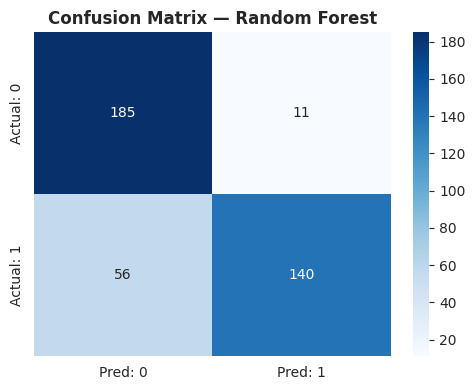

In [35]:
rf_base = RandomForestClassifier(random_state=RANDOM_STATE)
res_rf_base = evaluate_model('Random Forest',
                             rf_base, X_train_enc, X_test_enc, y_train, y_test)

### 7.2 XGBoost


  Model : XGBoost
  Accuracy  : 0.8597
  Precision : 0.9222
  Recall    : 0.7857
  F1-Score  : 0.8485
  ROC-AUC   : 0.8881

  Classification Report:
                    precision    recall  f1-score   support

Tidak Osteoporosis       0.81      0.93      0.87       196
      Osteoporosis       0.92      0.79      0.85       196

          accuracy                           0.86       392
         macro avg       0.87      0.86      0.86       392
      weighted avg       0.87      0.86      0.86       392



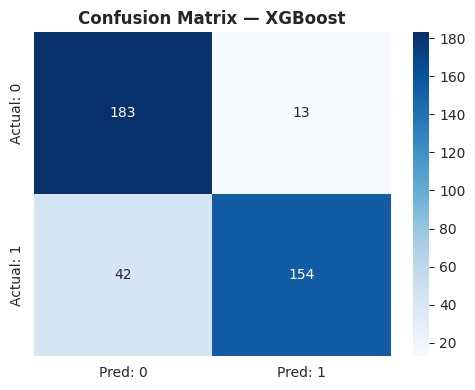

In [36]:
from xgboost import XGBClassifier

xgb_base = XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss')
res_xgb_base = evaluate_model('XGBoost',
                              xgb_base, X_train_enc, X_test_enc, y_train, y_test)

### 7.3 LightGBM


  Model : LightGBM
  Accuracy  : 0.8648
  Precision : 0.9333
  Recall    : 0.7857
  F1-Score  : 0.8532
  ROC-AUC   : 0.8849

  Classification Report:
                    precision    recall  f1-score   support

Tidak Osteoporosis       0.81      0.94      0.87       196
      Osteoporosis       0.93      0.79      0.85       196

          accuracy                           0.86       392
         macro avg       0.87      0.86      0.86       392
      weighted avg       0.87      0.86      0.86       392



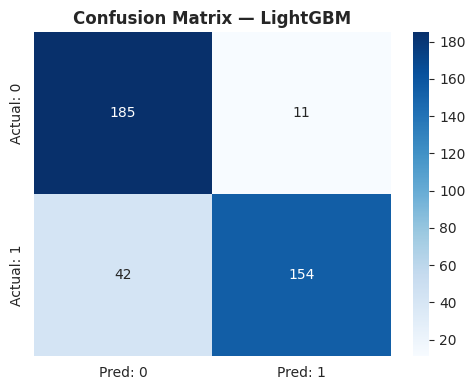

In [37]:
from lightgbm import LGBMClassifier

lgbm_base = LGBMClassifier(random_state=RANDOM_STATE, verbose=-1)
res_lgbm_base = evaluate_model('LightGBM',
                               lgbm_base, X_train_enc, X_test_enc, y_train, y_test)

### 7.4 Ringkasan Performa [Baseline]

In [38]:
results_baseline = pd.DataFrame([
    {k: v for k, v in r.items() if k != 'fitted_model'}
    for r in [res_rf_base, res_xgb_base, res_lgbm_base]
])
print('\n📊 Ringkasan Performa')
print(results_baseline.set_index('model').round(4).to_string())


📊 Ringkasan Performa
               accuracy  precision  recall      f1  roc_auc
model                                                      
Random Forest    0.8291     0.9272  0.7143  0.8069   0.8779
XGBoost          0.8597     0.9222  0.7857  0.8485   0.8881
LightGBM         0.8648     0.9333  0.7857  0.8532   0.8849


## 8. Hyperparameter Tuning dengan Optuna
**Rancangan tuning**
- Optuna (sampler TPE, `seed=RANDOM_STATE`) memaksimalkan skor **`SCORING`** (default F1) dengan **5-fold Stratified CV pada data train saja**.
- Data test tidak disentuh selama tuning. Data test hanya dipakai untuk evaluasi akhir.
- Setelah tuning, model dilatih ulang dengan parameter terbaik pada seluruh data train, lalu dievaluasi di data test dengan fungsi `evaluate_model` yang sama seperti baseline.
- Untuk mengganti metrik yang dioptimalkan, ubah `SCORING` di bagian Setup menjadi `"roc_auc"`.

In [39]:
cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)

def cv_score(model):
    """Rata-rata skor cross-validation (hanya data train)."""
    return cross_val_score(model, X_train_enc, y_train, cv=cv,
                           scoring=SCORING, n_jobs=-1).mean()

def buat_study(nama):
    return optuna.create_study(direction="maximize",
                               sampler=TPESampler(seed=RANDOM_STATE),
                               study_name=nama)

def tampilkan_hasil_study(study, waktu):
    print(f"\nWaktu tuning           : {waktu:.1f} detik")
    print(f"Skor CV terbaik ({SCORING}) : {study.best_value:.4f}")
    print("Hyperparameter terbaik :")
    for k, v in study.best_params.items():
        print(f"  {k:18s}: {v}")

print(f"Metrik objective : {SCORING}")
print(f"Jumlah trial     : {N_TRIALS} per model")
print(f"Validasi         : {N_FOLDS}-fold Stratified CV (data train)")

Metrik objective : f1
Jumlah trial     : 100 per model
Validasi         : 5-fold Stratified CV (data train)


### 8.1 Random Forest

In [40]:
def objective_rf(trial):
    params = {
        "n_estimators"     : trial.suggest_int("n_estimators", 100, 500, step=50),
        "max_depth"        : trial.suggest_int("max_depth", 3, 20),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 20),
        "min_samples_leaf" : trial.suggest_int("min_samples_leaf", 1, 10),
        "max_features"     : trial.suggest_categorical("max_features", ["sqrt", "log2", None]),
        "bootstrap"        : trial.suggest_categorical("bootstrap", [True, False]),
    }
    model = RandomForestClassifier(**params, random_state=RANDOM_STATE, n_jobs=1)
    return cv_score(model)

study_rf = buat_study("Random Forest")
t0 = time.time()
study_rf.optimize(objective_rf, n_trials=N_TRIALS, show_progress_bar=True)
tampilkan_hasil_study(study_rf, time.time() - t0)

  0%|          | 0/100 [00:00<?, ?it/s]


Waktu tuning           : 338.4 detik
Skor CV terbaik (f1) : 0.9141
Hyperparameter terbaik :
  n_estimators      : 200
  max_depth         : 12
  min_samples_split : 13
  min_samples_leaf  : 2
  max_features      : None
  bootstrap         : True



  Model : Random Forest [Tuned]
  Accuracy  : 0.8827
  Precision : 0.9934
  Recall    : 0.7704
  F1-Score  : 0.8678
  ROC-AUC   : 0.8912

  Classification Report:
                    precision    recall  f1-score   support

Tidak Osteoporosis       0.81      0.99      0.89       196
      Osteoporosis       0.99      0.77      0.87       196

          accuracy                           0.88       392
         macro avg       0.90      0.88      0.88       392
      weighted avg       0.90      0.88      0.88       392



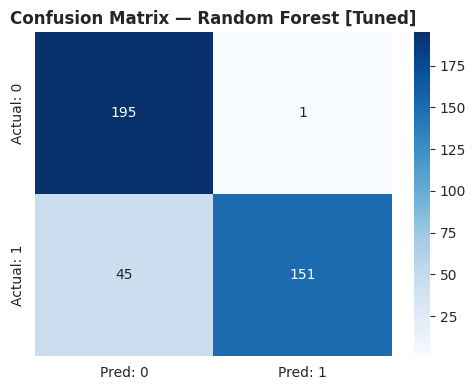

In [41]:
rf_tuned = RandomForestClassifier(**study_rf.best_params, random_state=RANDOM_STATE)
res_rf_tuned = evaluate_model('Random Forest [Tuned]',
                              rf_tuned, X_train_enc, X_test_enc, y_train, y_test)

### 8.2 XGBoost

In [42]:
def objective_xgb(trial):
    params = {
        "n_estimators"    : trial.suggest_int("n_estimators", 100, 600, step=50),
        "learning_rate"   : trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "max_depth"       : trial.suggest_int("max_depth", 3, 10),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "subsample"       : trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "reg_lambda"      : trial.suggest_float("reg_lambda", 1e-3, 10.0, log=True),
    }
    model = XGBClassifier(**params, random_state=RANDOM_STATE,
                          eval_metric="logloss", n_jobs=1)
    return cv_score(model)

study_xgb = buat_study("XGBoost")
t0 = time.time()
study_xgb.optimize(objective_xgb, n_trials=N_TRIALS, show_progress_bar=True)
tampilkan_hasil_study(study_xgb, time.time() - t0)

  0%|          | 0/100 [00:00<?, ?it/s]


Waktu tuning           : 66.4 detik
Skor CV terbaik (f1) : 0.9140
Hyperparameter terbaik :
  n_estimators      : 100
  learning_rate     : 0.021932598650327796
  max_depth         : 9
  min_child_weight  : 1
  subsample         : 0.7218940394332879
  colsample_bytree  : 0.5695220267057199
  reg_lambda        : 1.157032289197339



  Model : XGBoost [Tuned]
  Accuracy  : 0.8852
  Precision : 1.0000
  Recall    : 0.7704
  F1-Score  : 0.8703
  ROC-AUC   : 0.8909

  Classification Report:
                    precision    recall  f1-score   support

Tidak Osteoporosis       0.81      1.00      0.90       196
      Osteoporosis       1.00      0.77      0.87       196

          accuracy                           0.89       392
         macro avg       0.91      0.89      0.88       392
      weighted avg       0.91      0.89      0.88       392



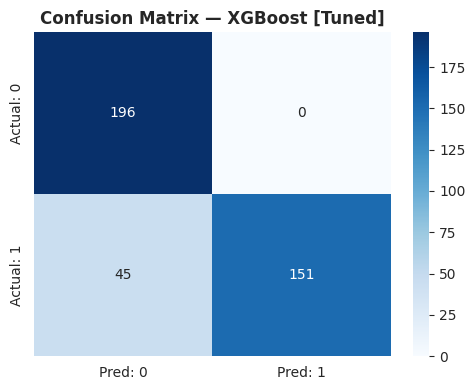

In [43]:
xgb_tuned = XGBClassifier(**study_xgb.best_params, random_state=RANDOM_STATE,
                          eval_metric="logloss")
res_xgb_tuned = evaluate_model('XGBoost [Tuned]',
                               xgb_tuned, X_train_enc, X_test_enc, y_train, y_test)

### 8.3 LightGBM

In [44]:
def objective_lgbm(trial):
    params = {
        "n_estimators"     : trial.suggest_int("n_estimators", 100, 600, step=50),
        "learning_rate"    : trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "num_leaves"       : trial.suggest_int("num_leaves", 15, 127),
        "max_depth"        : trial.suggest_int("max_depth", 3, 12),
        "min_child_samples": trial.suggest_int("min_child_samples", 5, 50),
        "subsample"        : trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree" : trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "reg_lambda"       : trial.suggest_float("reg_lambda", 1e-3, 10.0, log=True),
    }
    # subsample_freq=1 diperlukan agar parameter subsample benar-benar dipakai
    model = LGBMClassifier(**params, subsample_freq=1, random_state=RANDOM_STATE,
                           verbose=-1, n_jobs=1)
    return cv_score(model)

study_lgbm = buat_study("LightGBM")
t0 = time.time()
study_lgbm.optimize(objective_lgbm, n_trials=N_TRIALS, show_progress_bar=True)
tampilkan_hasil_study(study_lgbm, time.time() - t0)

  0%|          | 0/100 [00:00<?, ?it/s]


Waktu tuning           : 46.5 detik
Skor CV terbaik (f1) : 0.9091
Hyperparameter terbaik :
  n_estimators      : 150
  learning_rate     : 0.032755662716396544
  num_leaves        : 16
  max_depth         : 11
  min_child_samples : 7
  subsample         : 0.9916713662472548
  colsample_bytree  : 0.6331662069717294
  reg_lambda        : 0.0017804641446618743



  Model : LightGBM [Tuned]
  Accuracy  : 0.8827
  Precision : 0.9934
  Recall    : 0.7704
  F1-Score  : 0.8678
  ROC-AUC   : 0.8874

  Classification Report:
                    precision    recall  f1-score   support

Tidak Osteoporosis       0.81      0.99      0.89       196
      Osteoporosis       0.99      0.77      0.87       196

          accuracy                           0.88       392
         macro avg       0.90      0.88      0.88       392
      weighted avg       0.90      0.88      0.88       392



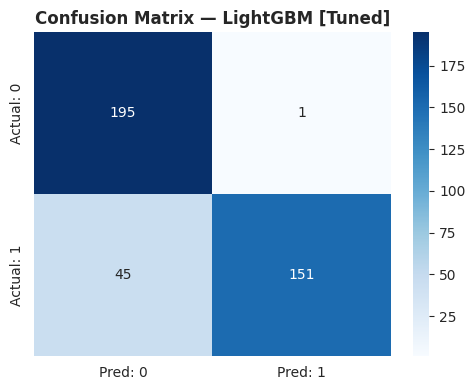

In [45]:
lgbm_tuned = LGBMClassifier(**study_lgbm.best_params, subsample_freq=1,
                            random_state=RANDOM_STATE, verbose=-1)
res_lgbm_tuned = evaluate_model('LightGBM [Tuned]',
                                lgbm_tuned, X_train_enc, X_test_enc, y_train, y_test)

## 9. Evaluasi: Baseline vs Tuned

### 9.1 Ringkasan Performa: Tuned

In [47]:
results_tuned = pd.DataFrame([
    {k: v for k, v in r.items() if k != 'fitted_model'}
    for r in [res_rf_tuned, res_xgb_tuned, res_lgbm_tuned]
])
print('Ringkasan Performa — Tuned Model (Optuna)')
print(results_tuned.set_index('model').round(4).to_string())

Ringkasan Performa — Tuned Model (Optuna)
                       accuracy  precision  recall      f1  roc_auc
model                                                              
Random Forest [Tuned]    0.8827     0.9934  0.7704  0.8678   0.8912
XGBoost [Tuned]          0.8852     1.0000  0.7704  0.8703   0.8909
LightGBM [Tuned]         0.8827     0.9934  0.7704  0.8678   0.8874


### 9.2 Tabel Perbandingan Baseline vs Tuned

In [48]:
metrik = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']
pasangan = [("Random Forest", res_rf_base,   res_rf_tuned),
            ("XGBoost",       res_xgb_base,  res_xgb_tuned),
            ("LightGBM",      res_lgbm_base, res_lgbm_tuned)]

baris = []
for nama, b, t in pasangan:
    baris.append({"algoritma": nama, "tahap": "Baseline", **{m: b[m] for m in metrik}})
    baris.append({"algoritma": nama, "tahap": "Tuned",    **{m: t[m] for m in metrik}})
    baris.append({"algoritma": nama, "tahap": "Selisih",  **{m: t[m] - b[m] for m in metrik}})

perbandingan = pd.DataFrame(baris).set_index(["algoritma", "tahap"])
print('📊 Perbandingan Baseline vs Tuned (Selisih = Tuned - Baseline)')
display(perbandingan.round(4))

📊 Perbandingan Baseline vs Tuned (Selisih = Tuned - Baseline)


accuracy  precision  recall      f1  roc_auc
algoritma     tahap                                                 
Random Forest Baseline    0.8291     0.9272  0.7143  0.8069   0.8779
              Tuned       0.8827     0.9934  0.7704  0.8678   0.8912
              Selisih     0.0536     0.0663  0.0561  0.0609   0.0133
XGBoost       Baseline    0.8597     0.9222  0.7857  0.8485   0.8881
              Tuned       0.8852     1.0000  0.7704  0.8703   0.8909
              Selisih     0.0255     0.0778 -0.0153  0.0218   0.0028
LightGBM      Baseline    0.8648     0.9333  0.7857  0.8532   0.8849
              Tuned       0.8827     0.9934  0.7704  0.8678   0.8874
              Selisih     0.0179     0.0601 -0.0153  0.0146   0.0025

### 9.3 Visualisasi Perbandingan Metrik

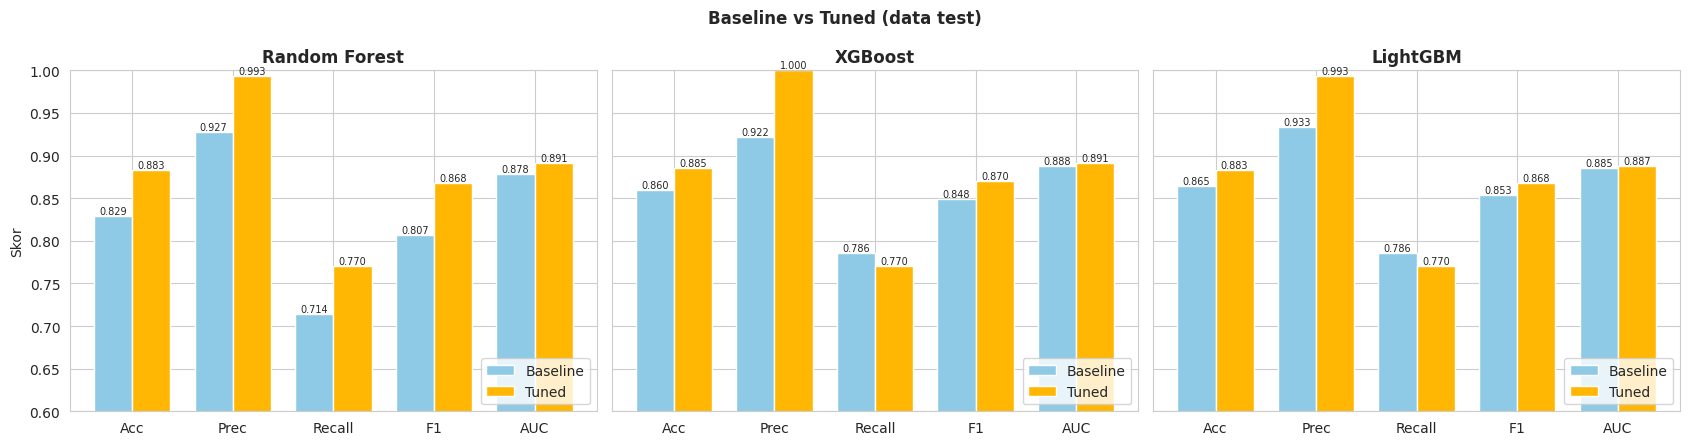

In [49]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), sharey=True)
lebar = 0.38
x = np.arange(len(metrik))

for ax, (nama, b, t) in zip(axes, pasangan):
    r1 = ax.bar(x - lebar/2, [b[m] for m in metrik], lebar, label="Baseline", color="#8ecae6")
    r2 = ax.bar(x + lebar/2, [t[m] for m in metrik], lebar, label="Tuned",    color="#ffb703")
    for rect in list(r1) + list(r2):
        ax.annotate(f"{rect.get_height():.3f}",
                    (rect.get_x() + rect.get_width()/2, rect.get_height()),
                    ha="center", va="bottom", fontsize=7)
    ax.set_title(nama, fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels(["Acc", "Prec", "Recall", "F1", "AUC"])
    ax.set_ylim(0.6, 1.0)
    ax.legend(loc="lower right")

axes[0].set_ylabel("Skor")
plt.suptitle("Baseline vs Tuned (data test)", fontweight="bold")
plt.tight_layout()
plt.show()

### 9.4 Tabel Hyperparameter Terbaik

In [50]:
best_params_all = {
    "Random Forest": study_rf.best_params,
    "XGBoost"      : study_xgb.best_params,
    "LightGBM"     : study_lgbm.best_params,
}
tabel_param = pd.DataFrame(
    [(m, k, v) for m, p in best_params_all.items() for k, v in p.items()],
    columns=["Model", "Parameter", "Nilai terbaik"]
)
display(tabel_param)

,Model,Parameter,Nilai terbaik
0,Random Forest,n_estimators,200
1,Random Forest,max_depth,12
2,Random Forest,min_samples_split,13
3,Random Forest,min_samples_leaf,2
4,Random Forest,max_features,None
5,Random Forest,bootstrap,True
6,XGBoost,n_estimators,100
7,XGBoost,learning_rate,0.021933
8,XGBoost,max_depth,9
9,XGBoost,min_child_weight,1


In [51]:
cek_cv = pd.DataFrame({
    "Model": ["Random Forest", "XGBoost", "LightGBM"],
    f"Skor CV terbaik ({SCORING}, train)": [study_rf.best_value, study_xgb.best_value, study_lgbm.best_value],
    f"Skor test ({SCORING})": [res_rf_tuned[SCORING], res_xgb_tuned[SCORING], res_lgbm_tuned[SCORING]],
}).set_index("Model")
cek_cv["Selisih (CV - test)"] = cek_cv.iloc[:, 0] - cek_cv.iloc[:, 1]
display(cek_cv.round(4))

,"Skor CV terbaik (f1, train)",Skor test (f1),Selisih (CV - test)
Model,,,
Random Forest,0.9141,0.8678,0.0463
XGBoost,0.9140,0.8703,0.0437
LightGBM,0.9091,0.8678,0.0413


## 10. Analisis Proses Optuna

### 10.1 Riwayat Optimasi

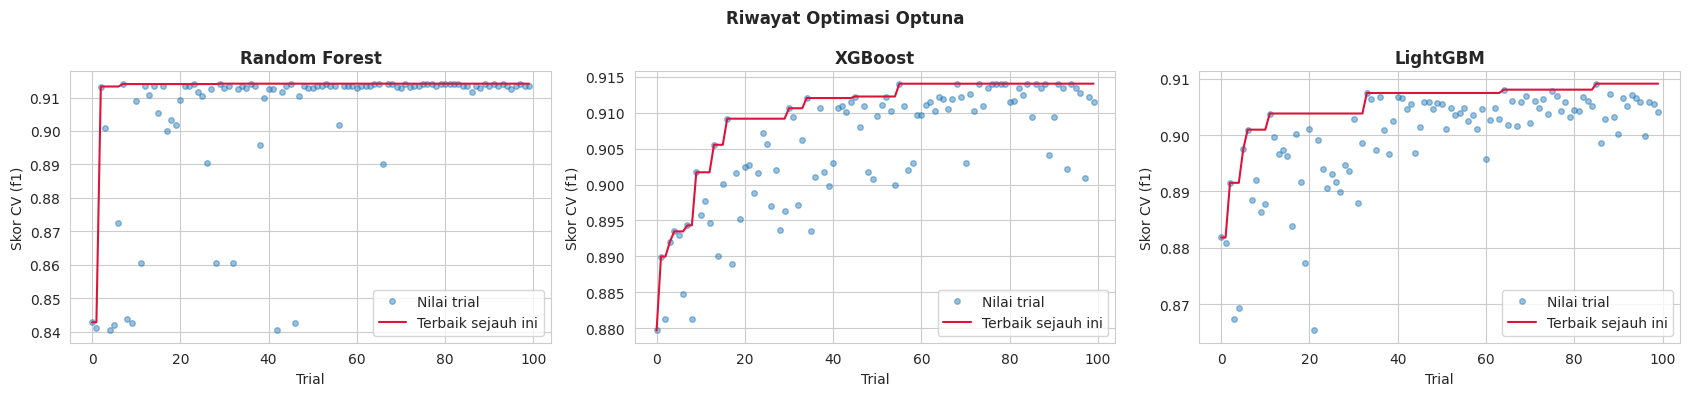

In [52]:
studies = {"Random Forest": study_rf, "XGBoost": study_xgb, "LightGBM": study_lgbm}

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, (nama, st) in zip(axes, studies.items()):
    nilai = [t.value for t in st.trials]
    terbaik = np.maximum.accumulate(nilai)
    ax.plot(nilai, "o", alpha=0.45, markersize=4, label="Nilai trial")
    ax.plot(terbaik, "-", color="crimson", label="Terbaik sejauh ini")
    ax.set_title(nama, fontweight="bold")
    ax.set_xlabel("Trial")
    ax.set_ylabel(f"Skor CV ({SCORING})")
    ax.legend(loc="lower right")
plt.suptitle("Riwayat Optimasi Optuna", fontweight="bold")
plt.tight_layout()
plt.show()

### 10.2 Pentingnya Hyperparameter

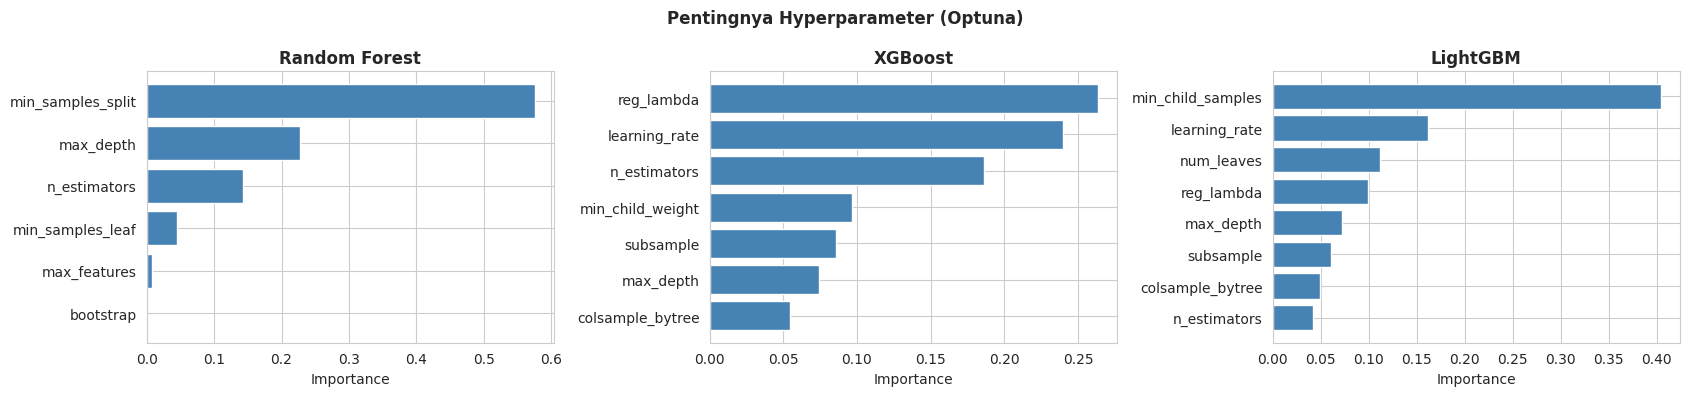

In [53]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, (nama, st) in zip(axes, studies.items()):
    try:
        imp = pd.Series(optuna.importance.get_param_importances(st)).sort_values()
        ax.barh(imp.index, imp.values, color="steelblue")
        ax.set_title(nama, fontweight="bold")
        ax.set_xlabel("Importance")
    except Exception as e:
        ax.set_title(f"{nama} (tidak tersedia)")
        print(nama, "->", e)
plt.suptitle("Pentingnya Hyperparameter (Optuna)", fontweight="bold")
plt.tight_layout()
plt.show()

## 11. Model Terbaik & Penyimpanan Hasil
Model terbaik dipilih dari keenam model (3 baseline + 3 tuned) berdasarkan **F1-Score di data test**, dengan ROC-AUC sebagai pemutus jika seri.

### 11.1 Peringkat Model

In [55]:
semua_hasil = [res_rf_base, res_xgb_base, res_lgbm_base,
               res_rf_tuned, res_xgb_tuned, res_lgbm_tuned]

ranking = (pd.DataFrame([{k: v for k, v in r.items() if k != 'fitted_model'} for r in semua_hasil])
           .sort_values(['f1', 'roc_auc'], ascending=False)
           .reset_index(drop=True))
ranking.index = ranking.index + 1
ranking.index.name = "peringkat"
display(ranking.round(4))

best_name = ranking.loc[1, 'model']
best_res  = next(r for r in semua_hasil if r['model'] == best_name)
print(f"\n🏆 Model terbaik : {best_name}")
print(f"   F1-Score      : {best_res['f1']:.4f}")
print(f"   ROC-AUC       : {best_res['roc_auc']:.4f}")

,model,accuracy,precision,recall,f1,roc_auc
peringkat,,,,,,
1,XGBoost [Tuned],0.8852,1.0000,0.7704,0.8703,0.8909
2,Random Forest [Tuned],0.8827,0.9934,0.7704,0.8678,0.8912
3,LightGBM [Tuned],0.8827,0.9934,0.7704,0.8678,0.8874
4,LightGBM,0.8648,0.9333,0.7857,0.8532,0.8849
5,XGBoost,0.8597,0.9222,0.7857,0.8485,0.8881
6,Random Forest,0.8291,0.9272,0.7143,0.8069,0.8779



🏆 Model terbaik : XGBoost [Tuned]
   F1-Score      : 0.8703
   ROC-AUC       : 0.8909


### 11.2 Kurva ROC Seluruh Model

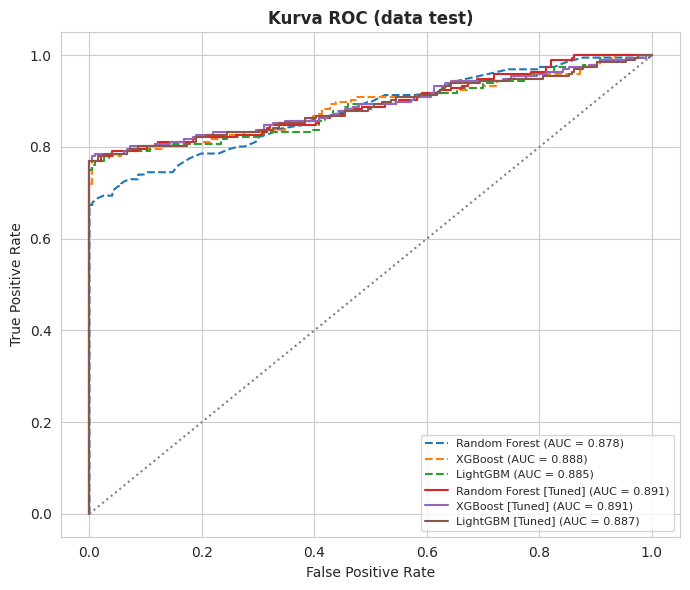

In [56]:
plt.figure(figsize=(7, 6))
for r in semua_hasil:
    fpr, tpr, _ = roc_curve(y_test, r['fitted_model'].predict_proba(X_test_enc)[:, 1])
    gaya = "-" if "Tuned" in r['model'] else "--"
    plt.plot(fpr, tpr, gaya, label=f"{r['model']} (AUC = {r['roc_auc']:.3f})")

plt.plot([0, 1], [0, 1], ":", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Kurva ROC (data test)", fontweight="bold")
plt.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()